# Performing GSM analysis for the projects of interest

In [ ]:
import cobra
from cobra.flux_analysis import pfba

from os import path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

In [2]:
# matplotlib default font
plt.rcParams['font.family'] = 'serif'
# Specify a preferred fallback list of fonts
plt.rcParams['font.serif'] = ['Times New Roman', 'DejaVu Serif']

# LOAD THE DATA DIRECTLY HERE

In [ ]:
# load the model
model = cobra.io.read_sbml_model('./required_data/iCTH669_for_RBA.sbml')

In [ ]:
# load the simulated data here
df_exp_sim_data = pd.read_csv('./results_characterize_imodulons/sulfur_ethanol/sim_data_sulfate_abrb_gsm.tsv', sep='\t', index_col=0)
df_exp_sim_data = df_exp_sim_data[['Sulfate', 'AbrB-Related', 'SO4_flux', 'etoh_yield', 'exp_etoh_conc', 'project']]

df_exp_sim_data.columns = ['Sulfate', 'AbrB-Related', 'SO4_flux_norm', 'etoh_yield', 'exp_etoh_conc', 'project']
df_exp_sim_data.sort_values('exp_etoh_conc', inplace=True) #sort these

df_exp_sim_data['SO4_flux_norm_abs'] = df_exp_sim_data['SO4_flux_norm'].abs()

# # create correlation matrix
df_exp_sim_data_for_corr = df_exp_sim_data.copy()
df_exp_sim_data_for_corr.drop('project', axis=1, inplace=True)
df_corr = df_exp_sim_data_for_corr.corr(method='spearman')
df_corr

,Sulfate,AbrB-Related,SO4_flux_norm,etoh_yield,exp_etoh_conc,SO4_flux_norm_abs
Sulfate,1.000000,0.631579,-0.798847,-0.710526,-0.722807,0.798847
AbrB-Related,0.631579,1.000000,-0.648541,-0.733333,-0.705263,0.648541
SO4_flux_norm,-0.798847,-0.648541,1.000000,0.639263,0.669881,-1.000000
etoh_yield,-0.710526,-0.733333,0.639263,1.000000,0.980702,-0.639263
exp_etoh_conc,-0.722807,-0.705263,0.669881,0.980702,1.000000,-0.669881
SO4_flux_norm_abs,0.798847,0.648541,-1.000000,-0.639263,-0.669881,1.000000


In [8]:
df_exp_sim_data.head(5)

,Sulfate,AbrB-Related,SO4_flux_norm,etoh_yield,exp_etoh_conc,project,SO4_flux_norm_abs
LL1160,-1.117030e+00,-1.484199e+00,-2.872076,1.047066,0.626000,EH,2.872076
LL376,-8.035441e-01,8.695266e-01,-3.165051,1.072156,0.641000,EH,3.165051
LL372,-6.853431e-01,1.184873e+00,-3.278195,1.073010,0.666000,EH,3.278195
LL345,-2.043080e+00,7.392149e-01,-3.164257,1.189240,0.711000,EH,3.164257
del_hpt:for0,-1.387779e-16,-2.775558e-16,-11.740442,1.199600,0.764762,evo,11.740442


### Plotting the sulfate data for all the non-engineered and engineered strains for projects -- eh_chemostat and evo_ag553_ag601

/var/folders/8c/yy8ts7rn59j58vl5_l6jgcmd1lvs3b/T/ipykernel_96625/3626725859.py:36: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


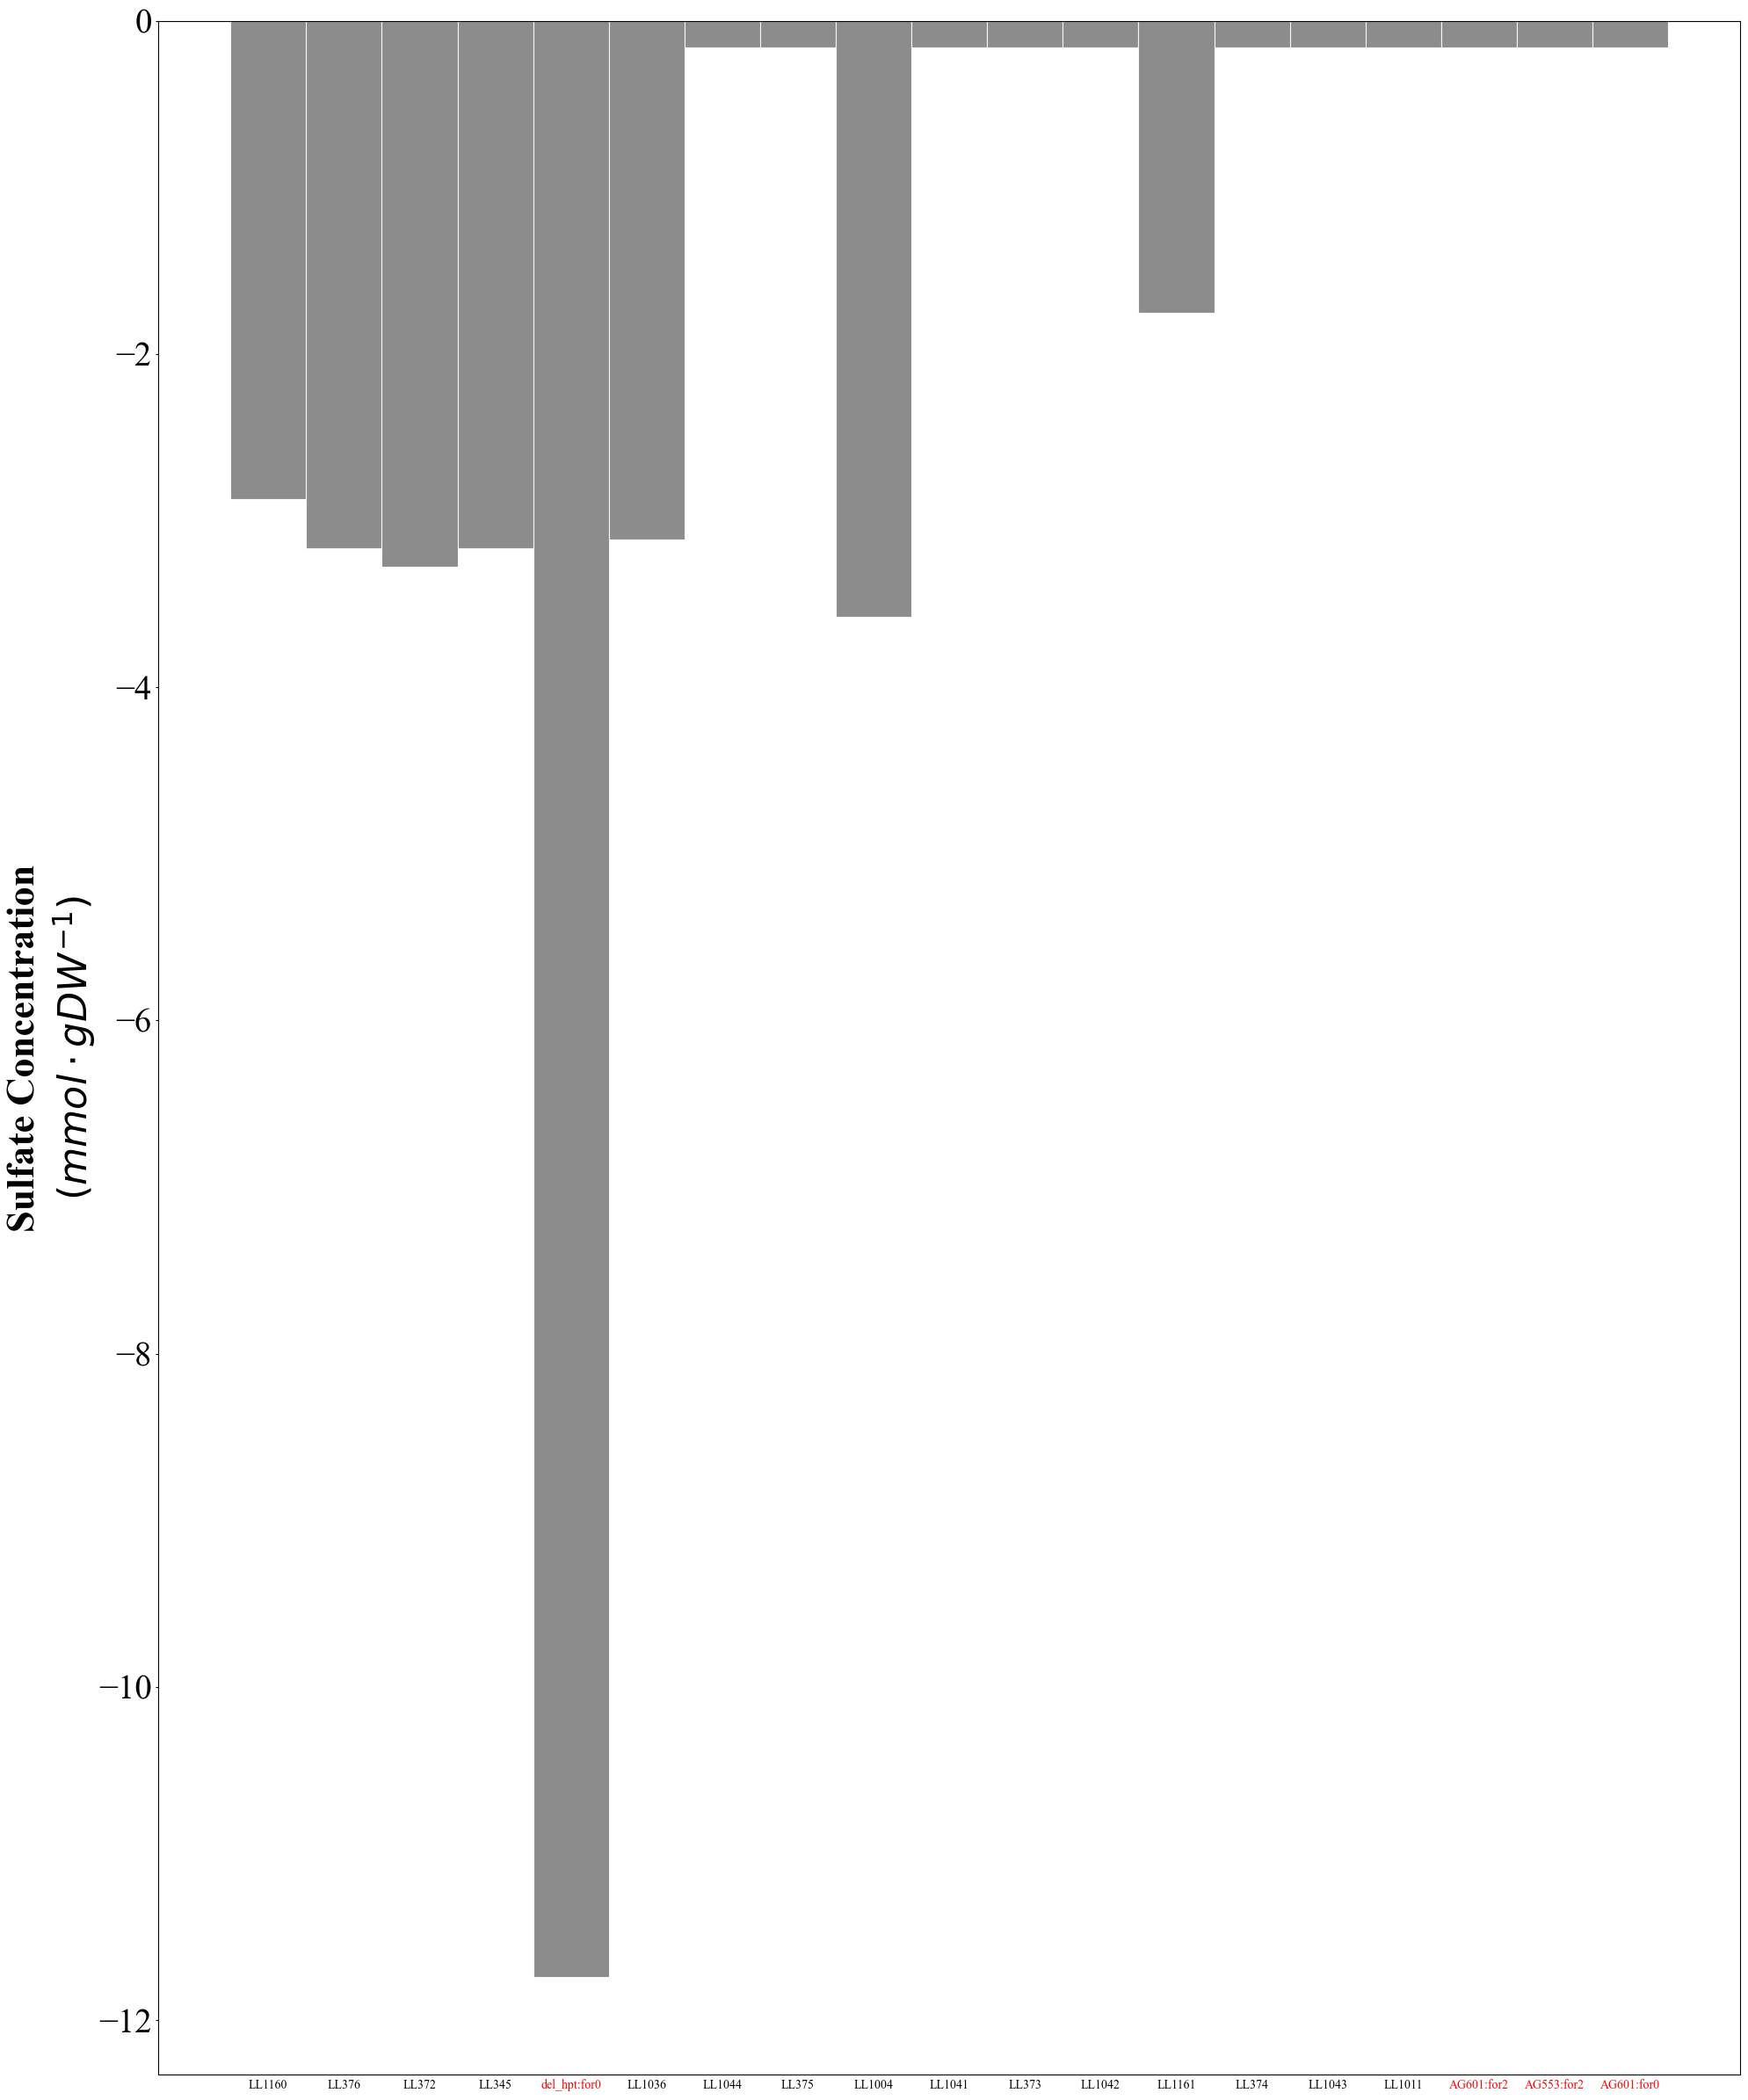

In [9]:
fig, ax = plt.subplots(1, 1, figsize=(20, 24), constrained_layout=True)

# ax = brokenaxes(ylims=((0, 4), (10, 12)), hspace=2)

# Pandas automatically uses df.index for x-ticks
ax.bar(
        df_exp_sim_data.index.to_list(),
        df_exp_sim_data['SO4_flux_norm'].values,
        color='grey', 
        alpha=0.9,
        width=1,
        edgecolor='white',
        linewidth=0.8,
        align='center',
        zorder=0.5
    )

# Remove the x-axis label title
ax.set_ylabel('Sulfate Concentration\n$(mmol \cdot gDW^{-1})$', fontdict={'size':32, 'weight':'bold'}, labelpad=0.5)

# add colors to different projects by iterating over the tick labels
group_colors = {'EH': 'black', 'evo': 'red'}

# 4. Iterate over the tick labels and apply the group colors
for tick_label in ax.get_xticklabels():
    col_name = tick_label.get_text()
    
    group = df_exp_sim_data.loc[col_name, 'project']
    if group:
        tick_label.set_color(group_colors[group])

# Remove tick marks but keep labels with certain label size for both axes
ax.tick_params(axis='y', length=2, labelsize=28)
ax.tick_params(axis='x', length=0)

plt.tight_layout()

# save plot
# plt.savefig('./results_characterize_imodulons/barplot_sulf_norm_in_mutants_gsm_res.png', transparent=True, pad_inches=0.01, dpi=300, format='png')

plt.show()

### Comparing two strains LL1004 and LL1011 to understand the cross-talk

In [16]:
df_sol_ll1004_ll1011 = pd.read_csv('./required_data/sim_data_ll1004_ll1011_solution_gsm.tsv', sep='\t', index_col=0)
df_sol_ll1004_ll1011.head()

,LL1004,LL1011
protein_biomass,0.09215,0.09025
NA_biomass,0.09215,0.09025
lipid_biomass,0.09215,0.09025
glyco_biomass,0.09215,0.09025
other_biomass,0.09215,0.09025


In [17]:
df_strain_flx = pd.DataFrame()
all_rxn = [(1, k.id) for k in model.reactions if not k.id.lower().endswith('biomass')] #all the reactions in the model except biomass reactions

for strain in df_sol_ll1004_ll1011.columns.to_list():    
    if df_sol_ll1004_ll1011.loc['status', strain]!='optimal':
        raise ValueError(f'Solution for {strain} is not optimal.')

    for rxn in all_rxn:
        df_strain_flx.loc[strain, rxn[1]] = df_sol_ll1004_ll1011.loc[rxn[1], strain]

/var/folders/8c/yy8ts7rn59j58vl5_l6jgcmd1lvs3b/T/ipykernel_96625/1106139341.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_strain_flx.loc[strain, rxn[1]] = df_sol_ll1004_ll1011.loc[rxn[1], strain]
/var/folders/8c/yy8ts7rn59j58vl5_l6jgcmd1lvs3b/T/ipykernel_96625/1106139341.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_strain_flx.loc[strain, rxn[1]] = df_sol_ll1004_ll1011.loc[rxn[1], strain]
/var/folders/8c/yy8ts7rn59j58vl5_l6jgcmd1lvs3b/T/ipykernel_96625/1106139341.py:9: PerformanceWarning: DataFrame is highly fr

In [18]:
sorted_idx = ['LL1004', 'LL1011']
df_strain_flx = df_strain_flx.loc[sorted_idx, :]

#filter the dataframe
df_strain_flx_v1 = df_strain_flx.loc[:, (df_strain_flx!=0).any(axis=0)]

df_strain_flx_v2 = df_strain_flx_v1.T #transpose

# convert to float values
df_strain_flx_v2 = df_strain_flx_v2.astype(float)

# compute difference
df_strain_flx_v2['LL1004'] = df_strain_flx_v2['LL1004'].round(3)
df_strain_flx_v2['LL1011'] = df_strain_flx_v2['LL1011'].round(3)
df_strain_flx_v2['difference'] = df_strain_flx_v2['LL1011'].abs() - df_strain_flx_v2['LL1004'].abs()
df_strain_flx_v2['difference'] = df_strain_flx_v2['difference'].round(3)

df_strain_flx_v2.sort_values('difference', ascending=False, inplace=True)


In [20]:
t_num=20 #top and bottom number of reactions to choose
df_strain_flx_combined = pd.concat([df_strain_flx_v2.head(t_num), df_strain_flx_v2.tail(t_num)])
df_strain_flx_combined['rxn'] = [model.reactions.get_by_id(k).reaction for k in df_strain_flx_combined.index.to_list()]

In [21]:
df_strain_flx_combined

,LL1004,LL1011,difference,rxn
RNF,0.833,6.049,5.216,2.0 fdxr_42_c + 2.0 h_c + nad_c <=> 2.0 fdxo_4...
ETOHt,2.696,6.659,3.963,etoh_c <=> etoh_e
ALCD2x,2.696,6.659,3.963,acald_c + h_c + nadh_c --> etoh_c + nad_c
EXCH_etoh_e,2.696,6.659,3.963,etoh_e -->
ACALD,2.696,6.659,3.963,accoa_c + h_c + nadh_c --> acald_c + coa_c + n...
PPDK,4.248,6.948,2.700,amp_c + h_c + pep_c + ppi_c <=> atp_c + pi_c +...
PGM,5.884,8.242,2.358,3pg_c <=> 2pg_c
ENO,5.884,8.242,2.358,2pg_c <=> h2o_c + pep_c
GAPD,6.000,8.355,2.355,g3p_c + nad_c + pi_c <=> 13dpg_c + h_c + nadh_c
POR,4.421,6.089,1.668,coa_c + 2.0 fdxo_42_c + pyr_c --> accoa_c + co...


### FIN